In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

HO_TEN = "Nguyễn Gia Huy"
MSSV = "6451071027"

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Câu 1: Nhập dữ liệu, cho biết số lượng dữ liệu huấn luyện và kiểm thử

In [3]:
print(HO_TEN, "-", MSSV)

COLS = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
        'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
        'hours-per-week', 'native-country', 'income']

def doc_file(path):
    # Bỏ qua dòng chú thích bắt đầu bằng '|' (có trong adult.test)
    df = pd.read_csv(path, header=None, skipinitialspace=True, comment='|')
    if str(df.iloc[0, 0]).strip().lower() == 'age':      # file đã có dòng tiêu đề
        df = pd.read_csv(path, skipinitialspace=True, comment='|')
    else:
        df.columns = COLS if df.shape[1] == len(COLS) else [c for c in COLS if c != 'fnlwgt']
    return df

train = doc_file('adult.data.csv')
test = doc_file('adult.test.csv')

print("Number of training data:", len(train))
print("Number of test data:", len(test))

Nguyễn Gia Huy - 6451071027
Number of training data: 32561
Number of test data: 16281


## Câu 2: Tiền xử lý dữ liệu

In [4]:
print(HO_TEN, "-", MSSV)

# Xóa các dòng chứa dữ liệu trống (ký hiệu '?')
def xoa_dong_trong(df):
    df = df.copy()
    for c in df.select_dtypes(include='object').columns:
        df[c] = df[c].astype(str).str.strip()
    df = df.replace('?', np.nan).dropna()
    return df.reset_index(drop=True)

train = xoa_dong_trong(train)
test = xoa_dong_trong(test)

# Xóa cột final weight 'fnlwgt'
train = train.drop('fnlwgt', axis=1, errors='ignore')
test = test.drop('fnlwgt', axis=1, errors='ignore')

# Chuẩn hóa nhãn (adult.test có dấu '.' ở cuối: '<=50K.' -> '<=50K')
train['income'] = train['income'].str.rstrip('.')
test['income'] = test['income'].str.rstrip('.')

print("Number of training data:", len(train))
print("Number of test data:", len(test))

# Nối dữ liệu huấn luyện và kiểm thử
n_train = len(train)
data = pd.concat([train, test], ignore_index=True)
data.info()

Nguyễn Gia Huy - 6451071027
Number of training data: 30162
Number of test data: 15060
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             45222 non-null  int64 
 1   workclass       45222 non-null  object
 2   education       45222 non-null  object
 3   education-num   45222 non-null  int64 
 4   marital-status  45222 non-null  object
 5   occupation      45222 non-null  object
 6   relationship    45222 non-null  object
 7   race            45222 non-null  object
 8   sex             45222 non-null  object
 9   capital-gain    45222 non-null  int64 
 10  capital-loss    45222 non-null  int64 
 11  hours-per-week  45222 non-null  int64 
 12  native-country  45222 non-null  object
 13  income          45222 non-null  object
dtypes: int64(5), object(9)
memory usage: 4.8+ MB


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson

Nguyễn Gia Huy - 6451071027


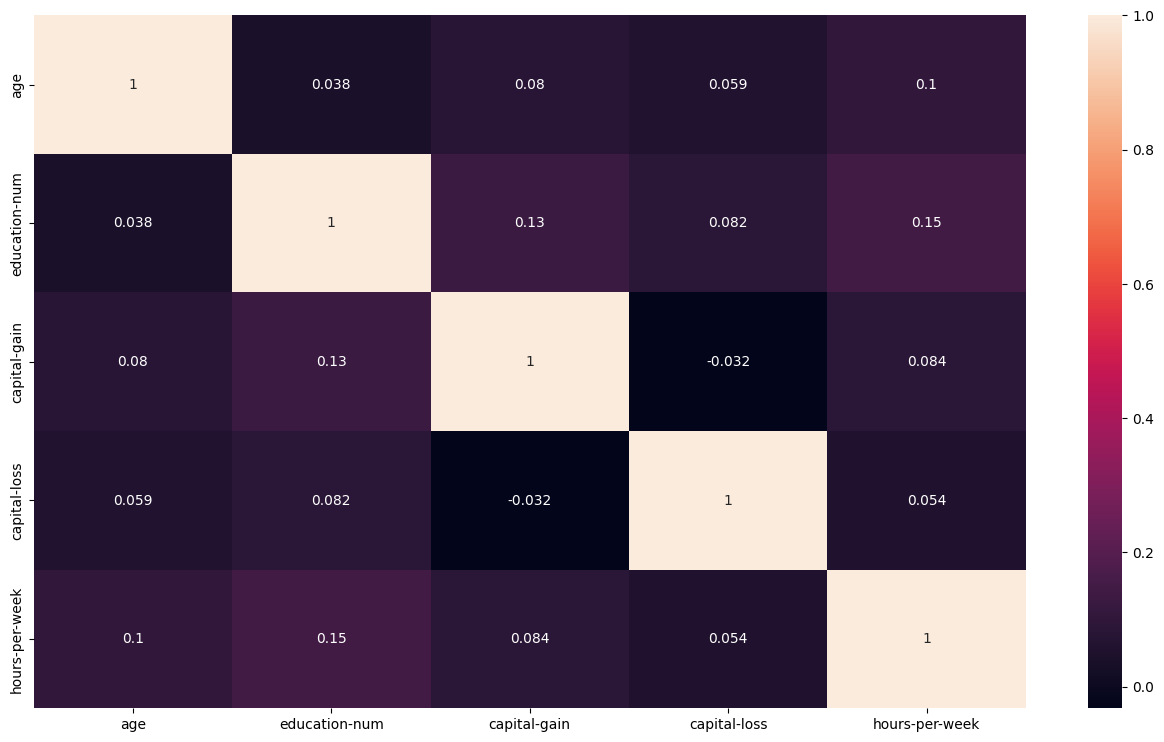

Các cột bị loại bỏ: []


In [5]:
print(HO_TEN, "-", MSSV)

plt.figure(figsize=(16, 9))
sns.heatmap(data.corr(method='pearson', numeric_only=True), annot=True)
plt.show()

# Loại bỏ các cột có độ tương đồng cao (|r| > 0.8)
corr = data.corr(method='pearson', numeric_only=True).abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
cot_loai_bo = [c for c in upper.columns if (upper[c] > 0.8).any()]
print("Các cột bị loại bỏ:", cot_loai_bo)
data = data.drop(columns=cot_loai_bo)

## Câu 4: Tách các cột thành thuộc tính bình thường và thuộc tính quyết định

In [6]:
print(HO_TEN, "-", MSSV)

features = data.drop('income', axis=1)
labels = data['income']
print(features.shape, labels.shape)

Nguyễn Gia Huy - 6451071027
(45222, 13) (45222,)


## Câu 5: Chuyển các cột không phải dạng số về dạng one-hot vector

In [7]:
print(HO_TEN, "-", MSSV)

print(features.select_dtypes(exclude=['int64']).columns)

features_onehot = pd.get_dummies(features, columns=features.select_dtypes(exclude=['int64']).columns)
features_onehot

Nguyễn Gia Huy - 6451071027
Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,50,13,0,0,13,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False
2,38,9,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
3,53,7,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
4,28,13,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45217,33,13,0,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
45218,39,13,0,0,36,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
45219,38,13,0,0,50,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
45220,44,13,5455,0,40,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False


## Câu 6: Tách các dòng dữ liệu thành hai phần huấn luyện và kiểm thử như ban đầu

In [8]:
print(HO_TEN, "-", MSSV)

X_train = features_onehot[:n_train]
X_test = features_onehot[n_train:]
y_train = labels[:n_train]
y_test = labels[n_train:]
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

Nguyễn Gia Huy - 6451071027
(30162, 103) (15060, 103) (30162,) (15060,)


## Câu 7: Xây dựng cây ID3, kiểm thử bằng ma trận nhầm lẫn, biểu diễn cây

In [9]:
print(HO_TEN, "-", MSSV)

clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
#Train Decision Tree Classifer
clf.fit(X_train, y_train)

Nguyễn Gia Huy - 6451071027


DecisionTreeClassifier(criterion='entropy', random_state=0)

In [10]:
print(HO_TEN, "-", MSSV)
#Predict the response for test dataset
tree_pred = clf.predict(X_test)

# Model Accuracy, how often is the classifier correct?
tree_score = metrics.accuracy_score(y_test, tree_pred)
print("Accuracy:", tree_score)
print("Report:", metrics.classification_report(y_test, tree_pred))

Nguyễn Gia Huy - 6451071027
Accuracy: 0.8175298804780876
Report:               precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88     11360
        >50K       0.63      0.62      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.82      0.82      0.82     15060



Nguyễn Gia Huy - 6451071027


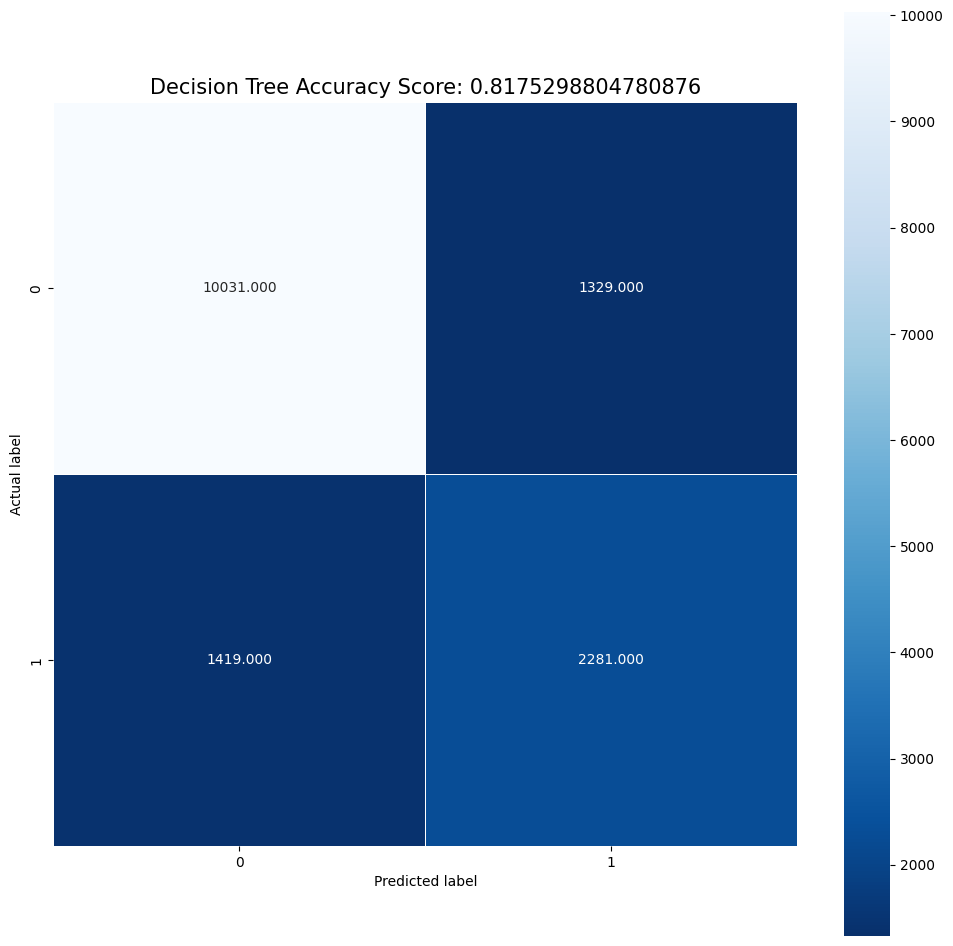

In [11]:
print(HO_TEN, "-", MSSV)
tree_cm = metrics.confusion_matrix(y_test, tree_pred)

plt.figure(figsize=(12,12))
sns.heatmap(tree_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Decision Tree Accuracy Score: {0}'.format(tree_score)
plt.title(title, size=15);

Nguyễn Gia Huy - 6451071027


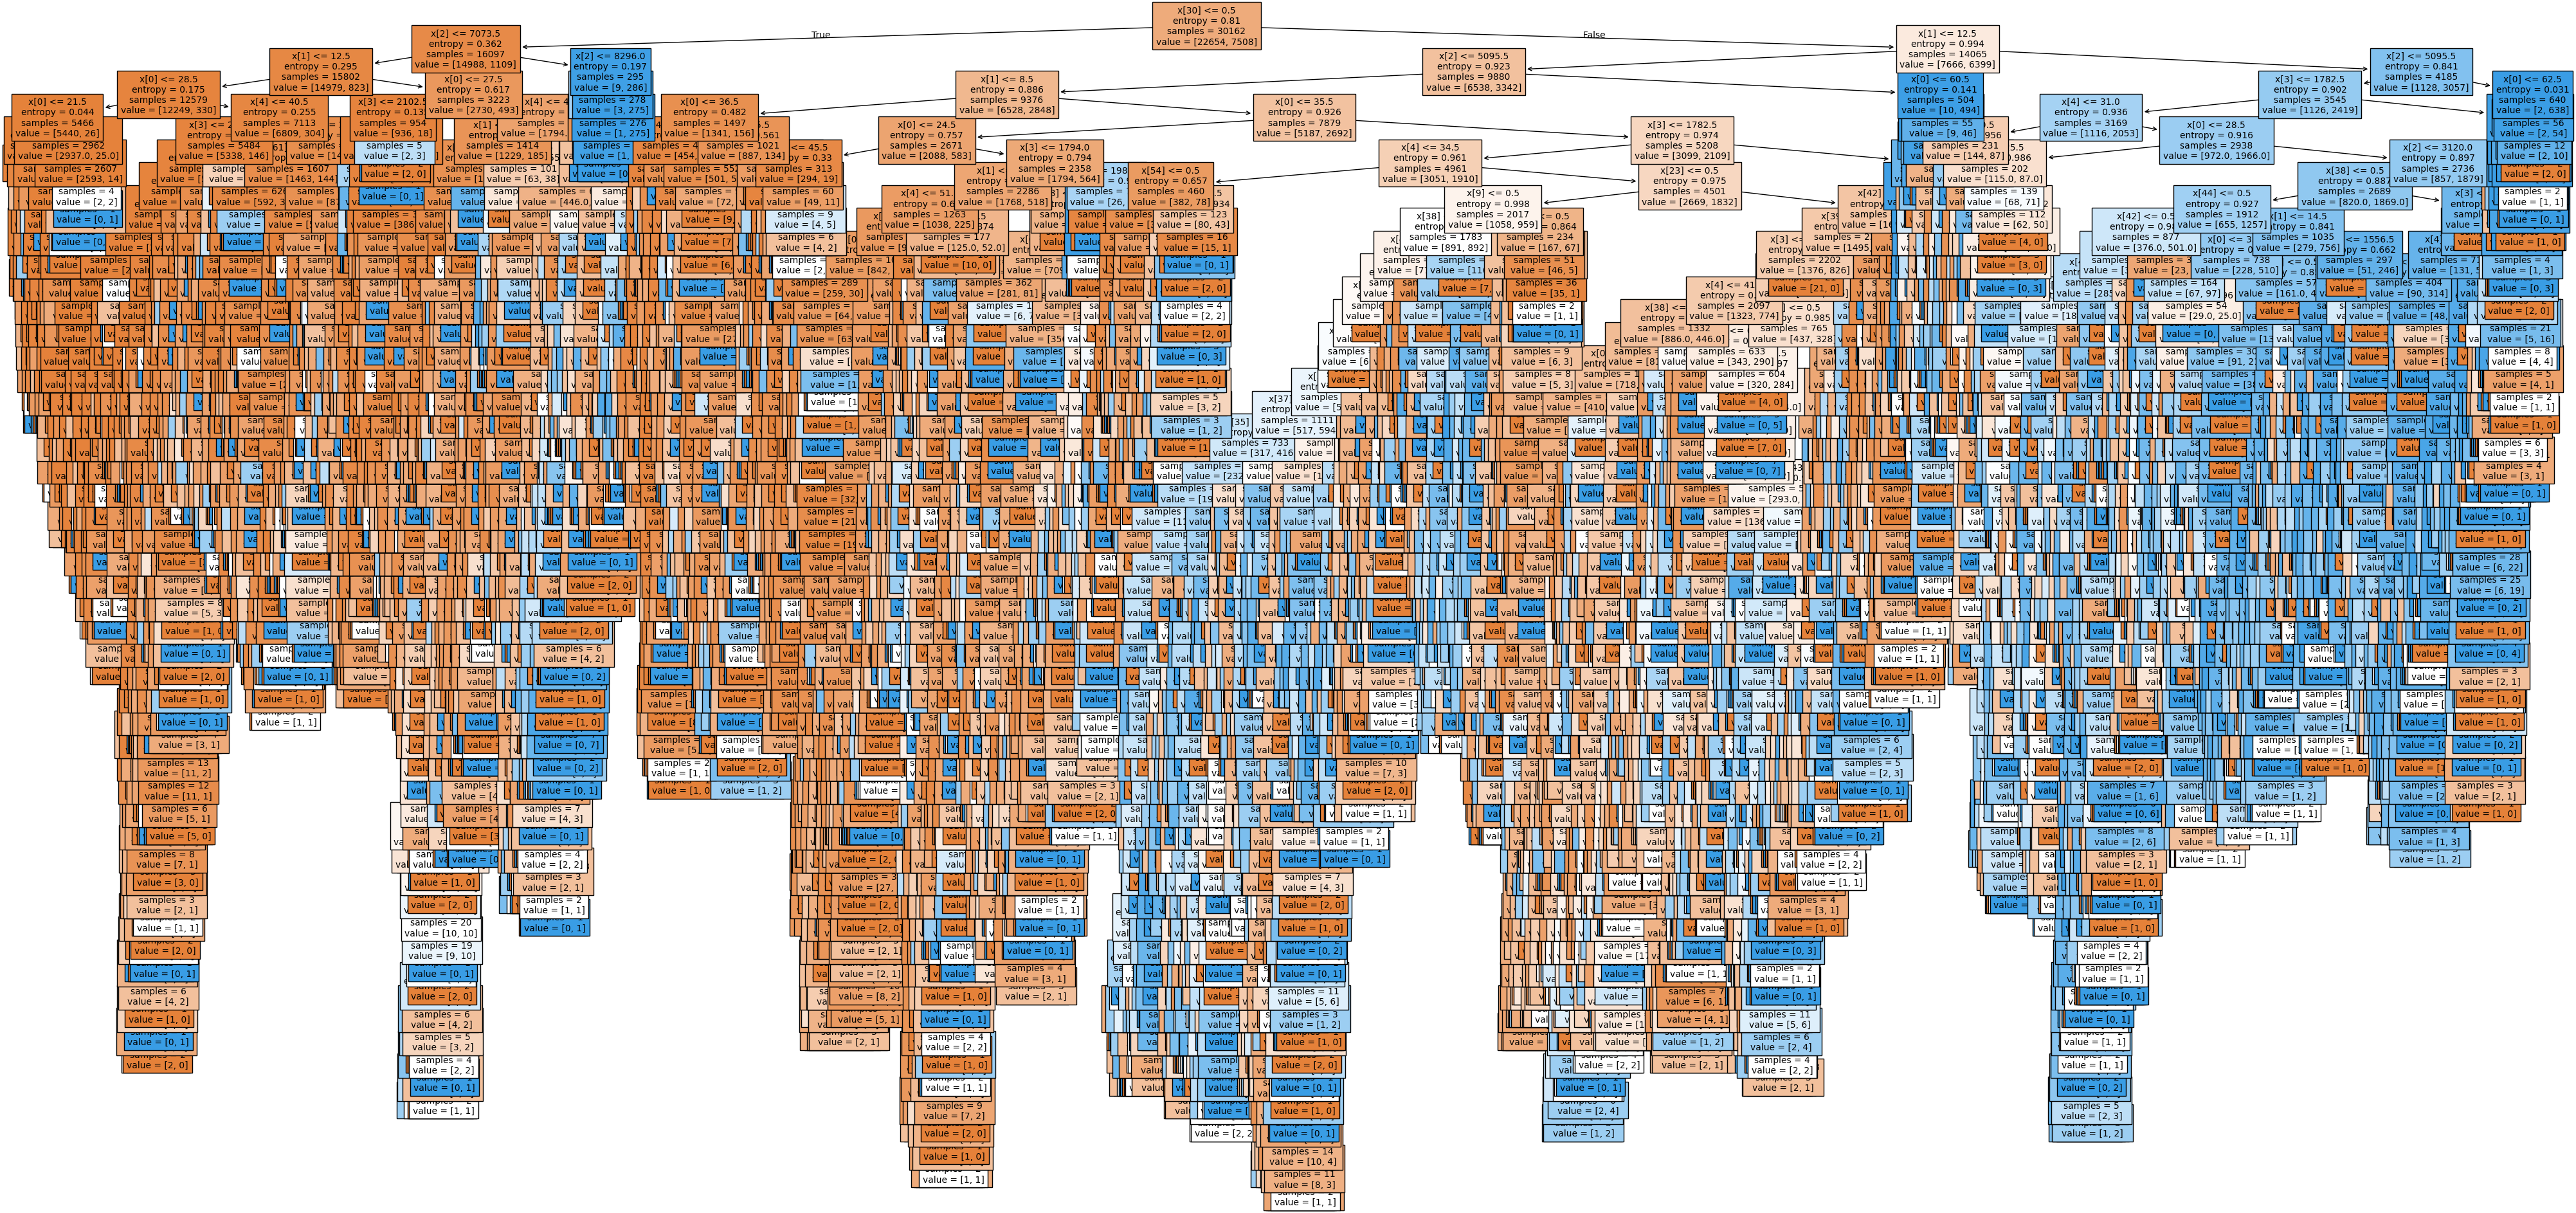

In [12]:
print(HO_TEN, "-", MSSV)
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf, filled=True, fontsize=10)
plt.savefig('decision_tree', dpi=100)
plt.show()

## Câu 8: Xây dựng cây CART (criterion='gini')

In [13]:
print(HO_TEN, "-", MSSV)

clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
#Train Decision Tree Classifer
clf_cart.fit(X_train, y_train)

Nguyễn Gia Huy - 6451071027


DecisionTreeClassifier(random_state=0)

In [14]:
print(HO_TEN, "-", MSSV)
#Predict the response for test dataset
cart_pred = clf_cart.predict(X_test)

# Model Accuracy, how often is the classifier correct?
cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy:", cart_score)
print("Report:", metrics.classification_report(y_test, cart_pred))

Nguyễn Gia Huy - 6451071027
Accuracy: 0.8122841965471448
Report:               precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.74     15060
weighted avg       0.81      0.81      0.81     15060



Nguyễn Gia Huy - 6451071027


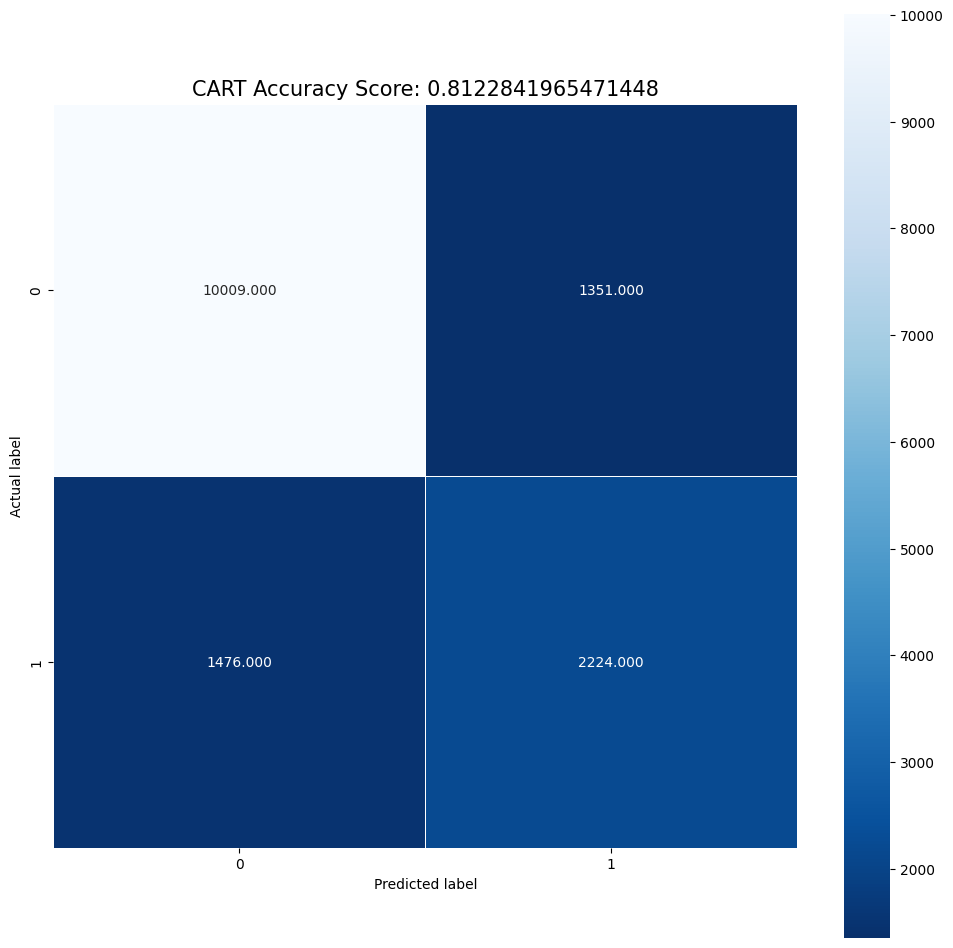

In [15]:
print(HO_TEN, "-", MSSV)
cart_cm = metrics.confusion_matrix(y_test, cart_pred)

plt.figure(figsize=(12,12))
sns.heatmap(cart_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'CART Accuracy Score: {0}'.format(cart_score)
plt.title(title, size=15);

Nguyễn Gia Huy - 6451071027


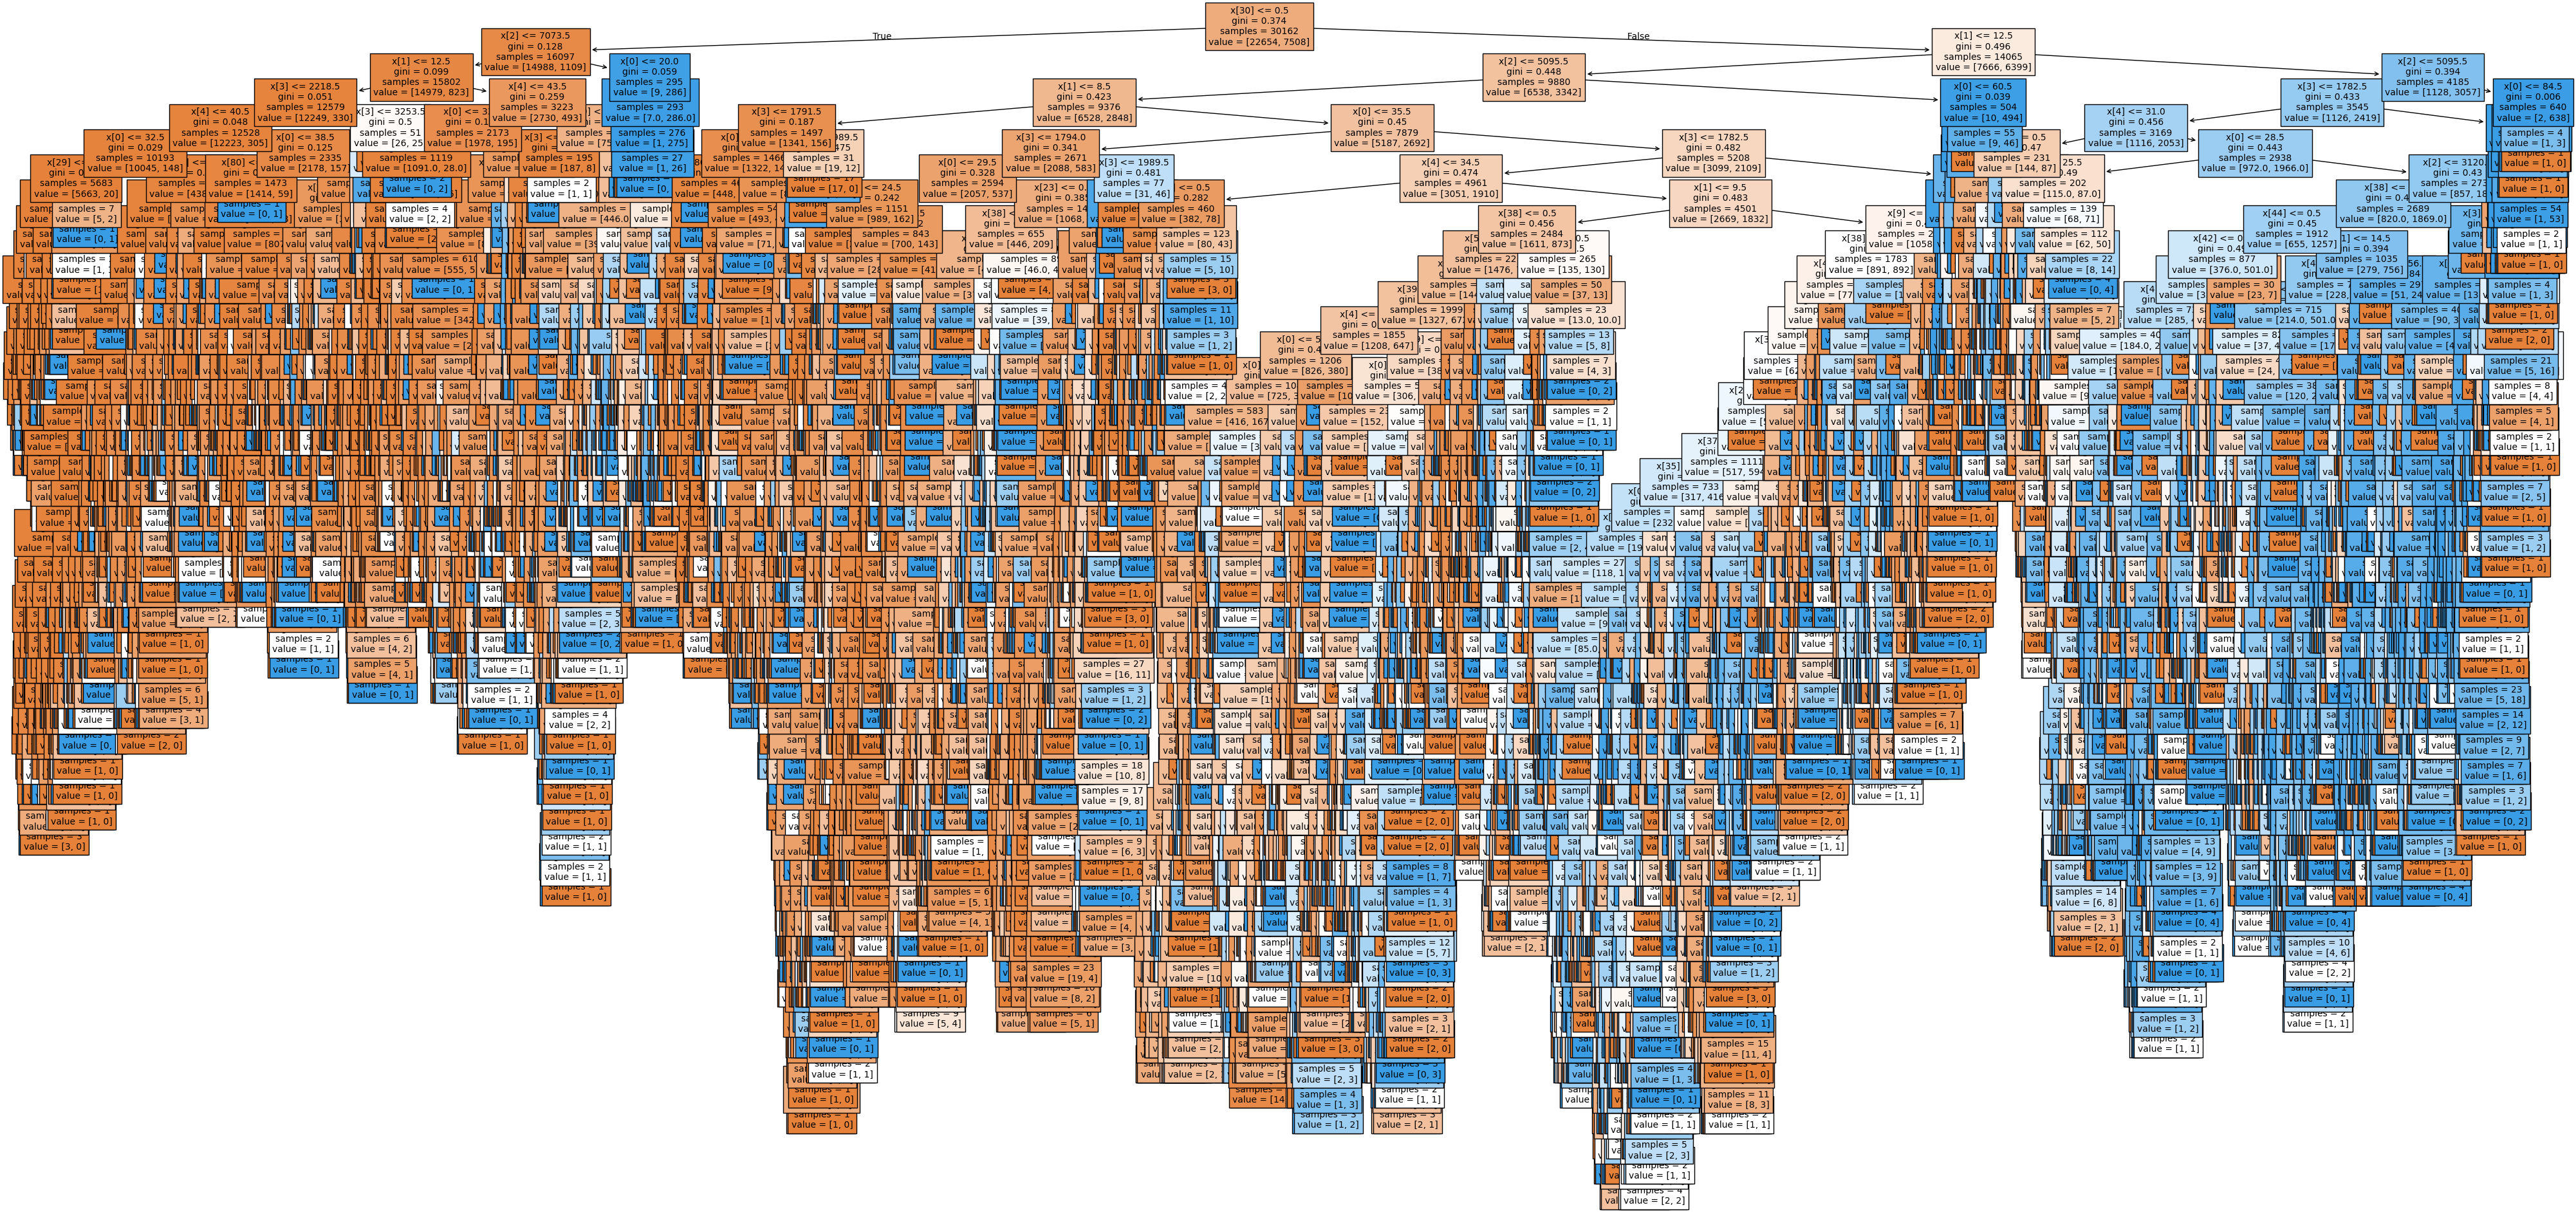

In [16]:
print(HO_TEN, "-", MSSV)
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf_cart, filled=True, fontsize=10)
plt.savefig('decision_tree_cart', dpi=100)
plt.show()

## Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes

In [17]:
print(HO_TEN, "-", MSSV)

gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

Nguyễn Gia Huy - 6451071027


In [18]:
print(HO_TEN, "-", MSSV)
# Model Accuracy, how often is the classifier correct?
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:", metrics.classification_report(y_test, bayes_pred))

Nguyễn Gia Huy - 6451071027
Accuracy: 0.8029216467463479
Report:               precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060



Nguyễn Gia Huy - 6451071027


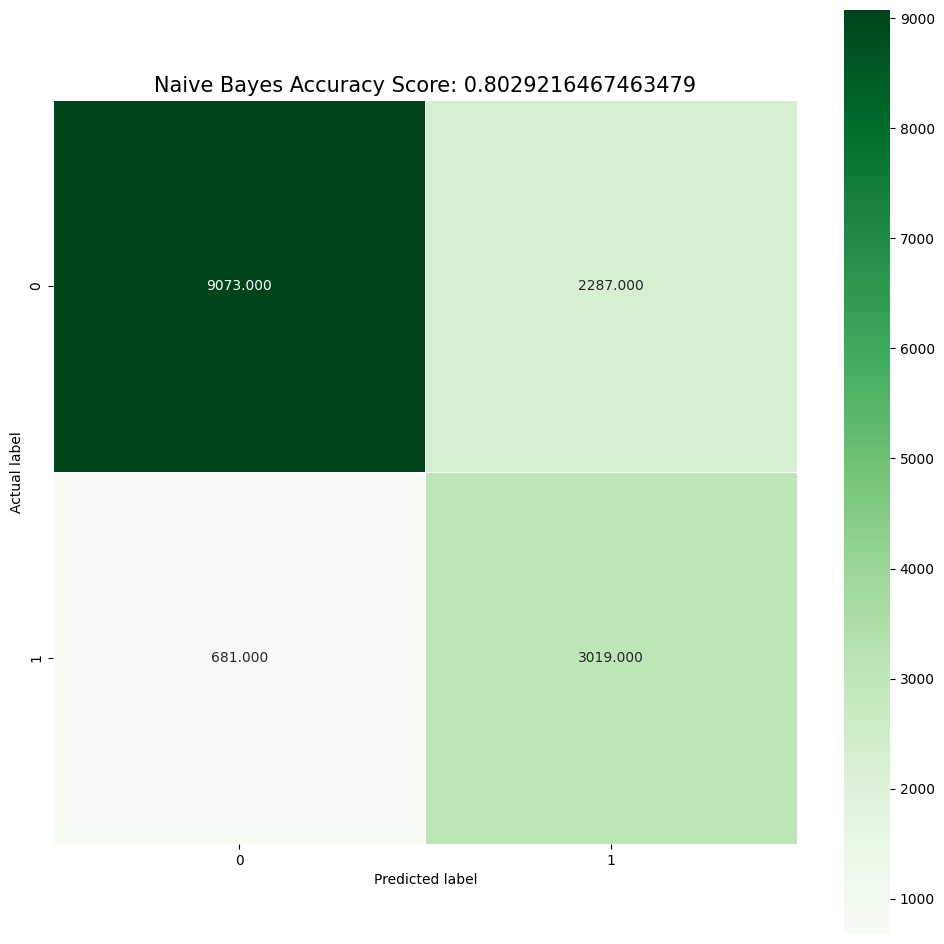

In [19]:
print(HO_TEN, "-", MSSV)
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)

plt.figure(figsize=(12,12))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Greens');
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Naive Bayes Accuracy Score: {0}'.format(bayes_score)
plt.title(title, size=15);

## Câu 10: So sánh kết quả của các mô hình

In [20]:
print(HO_TEN, "-", MSSV)

ket_qua = {'ID3': tree_pred, 'CART': cart_pred, 'Naive Bayes': bayes_pred}
bang = pd.DataFrame({
    ten: {
        'Accuracy': metrics.accuracy_score(y_test, pred),
        'Precision (>50K)': metrics.precision_score(y_test, pred, pos_label='>50K'),
        'Recall (>50K)': metrics.recall_score(y_test, pred, pos_label='>50K'),
        'F1-score (>50K)': metrics.f1_score(y_test, pred, pos_label='>50K'),
        'Precision (macro avg)': metrics.precision_score(y_test, pred, average='macro'),
        'Recall (macro avg)': metrics.recall_score(y_test, pred, average='macro'),
        'F1-score (macro avg)': metrics.f1_score(y_test, pred, average='macro'),
    } for ten, pred in ket_qua.items()
}).round(4)
bang

Nguyễn Gia Huy - 6451071027


,ID3,CART,Naive Bayes
Accuracy,0.8175,0.8123,0.8029
Precision (>50K),0.6319,0.6221,0.5690
Recall (>50K),0.6165,0.6011,0.8159
F1-score (>50K),0.6241,0.6114,0.6704
Precision (macro avg),0.7540,0.7468,0.7496
Recall (macro avg),0.7497,0.7411,0.8073
F1-score (macro avg),0.7518,0.7438,0.7649


Nguyễn Gia Huy - 6451071027


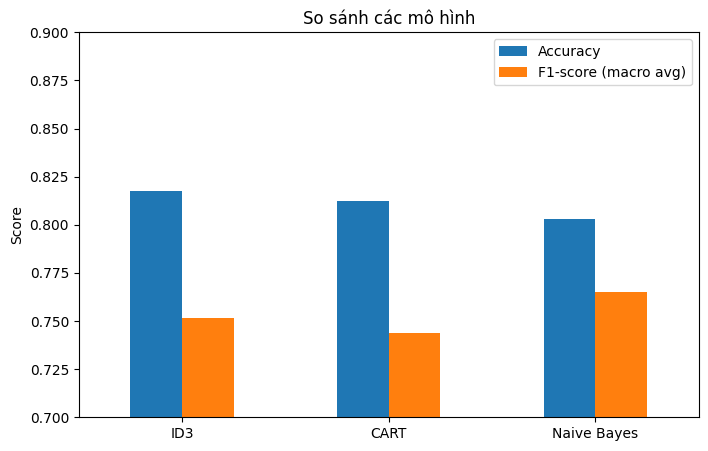

In [21]:
print(HO_TEN, "-", MSSV)
bang.T[['Accuracy', 'F1-score (macro avg)']].plot(kind='bar', figsize=(8, 5), rot=0)
plt.title('So sánh các mô hình')
plt.ylabel('Score')
plt.ylim(0.7, 0.9)
plt.show()